<a href="https://colab.research.google.com/github/Ravna95/Capstone-Project/blob/main/DataCo_Smart_Supply_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [4]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [5]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [6]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [7]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [8]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [10]:
#this was inserted from Master Phyton notebook#
import os
import pandas as pd

# --- STEP 1: Verify Current Directory & Files ---
print('Current Working Directory:', os.getcwd())
print('Files available in folder:', os.listdir('.'))


# --- STEP 2: Handle Missing Values ---
# Products: Fill missing descriptions
products['Product Description'] = products['Product Description'].fillna(
    'No Description'
)

# Customers: Fill missing zipcodes
customers['Customer Zipcode'] = customers['Customer Zipcode'].fillna(0)

# Geography: Fill missing zipcodes and states
geography['Order Zipcode'] = geography['Order Zipcode'].fillna(0)
geography['Order State'] = geography['Order State'].fillna('Unknown')

# --- STEP 3: Merge All Datasets into One Master DataFrame ---
print('\nMerging datasets...')
master = order_items.merge(orders, on='Order Id', how='left', suffixes=('', '_order'))
master = master.merge(shipping, on='Shipment_Id', how='left')
master = master.merge(payment_types, on='Payment_Type_ID', how='left')
master = master.merge(geography, on='Location_Id', how='left')
master = master.merge(
    customers,
    left_on='Order Customer Id',
    right_on='Customer Id',
    how='left',
    suffixes=('', '_cust'),
)
master = master.merge(products, on='Product Card Id', how='left')
master = master.merge(
    categories, left_on='Product Category Id', right_on='Category Id', how='left'
)
master = master.merge(departments, on='Department Id', how='left')

# --- STEP 4: Save and Verify Final Dataset ---
master.to_csv('master_supply_chain.csv', index=False)
print('\nSuccess! master_supply_chain.csv has been created and saved.')

# Load back to check
df = pd.read_csv('master_supply_chain.csv')
print(f'Final Master Dataset Shape: {df.shape}')
print('\nFirst 3 rows preview:')
print(df.head(3))

Current Working Directory: /content
Files available in folder: ['.config', 'images', 'master_supply_chain.csv', 'sample_data']

Merging datasets...

Success! master_supply_chain.csv has been created and saved.
Final Master Dataset Shape: (180519, 57)

First 3 rows preview:
   Order Item Id  Order Id  Order Item Cardprod Id  Product Card Id  \
0         180517     77202                    1360             1360   
1         179254     75939                    1360             1360   
2         179253     75938                    1360             1360   

   Customer Id  Order Item Discount  Order Item Discount Rate  \
0        20755            13.110000                      0.04   
1        19492            16.389999                      0.05   
2        19491            18.030001                      0.06   

   Order Item Product Price  Order Item Profit Ratio  Order Item Quantity  \
0                    327.75                     0.29                    1   
1                    327.7

In [11]:
import pandas as pd

# 1. Load your master CSV
df = pd.read_csv('master_supply_chain.csv')

# 2. Convert date columns to datetime objects
df['order_date'] = pd.to_datetime(df['order date (DateOrders)'], errors='coerce')
df['shipping_date'] = pd.to_datetime(df['shipping date (DateOrders)'], errors='coerce')

# 3. Create temporal features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 4. Create supply chain and profit metrics
df['Shipping_Delay_Variance'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']
df['Is_Profitable'] = df['Order Profit Per Order'].apply(lambda x: 1 if x > 0 else 0)

# 5. Save it permanently back to the CSV file
df.to_csv('master_supply_chain.csv', index=False)

print(f"Success! Updated dataset saved. New shape: {df.shape}")

Success! Updated dataset saved. New shape: (180519, 66)


In [9]:
# 1. Run all your preprocessing & feature engineering code...

# 2. SAVE it permanently to your CSV file
df.to_csv('master_supply_chain.csv', index=False)

print("Master supply chain dataset successfully saved with all engineered features!")

Master supply chain dataset successfully saved with all engineered features!


In [ ]:
df.to_csv('master_supply_chain.csv', index=False)

OBJECTIVE 1: EXECUTIVE SUMMARY METRICS
Total Sales Revenue      : $36,784,735.01
Total Net Profit         : $3,966,902.97
Overall Profit Margin    : 10.78%
Total Unique Orders      : 65,752


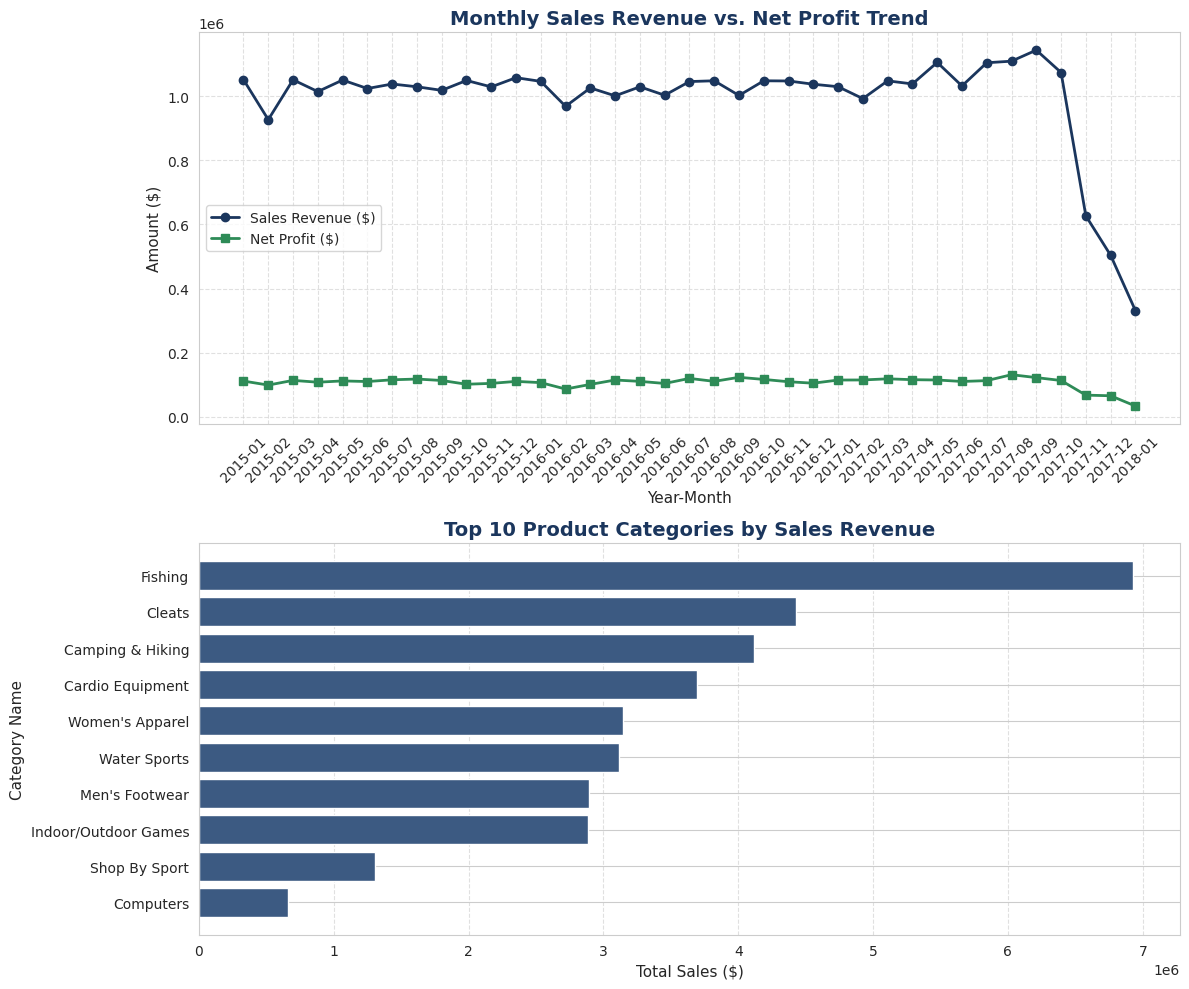


Visuals saved successfully to 'images/objective_1_sales_performance.png'.


In [12]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Ensure visualizations directory exists
os.makedirs('images', exist_ok=True)

# 1. Load the master dataset
df = pd.read_csv('master_supply_chain.csv')

# 2. Calculate Key Sales Metrics
total_sales = df['Sales'].sum()
total_profit = df['Order Profit Per Order'].sum()
overall_profit_margin = (total_profit / total_sales) * 100
total_orders = df['Order Id'].nunique()

print("="*50)
print("OBJECTIVE 1: EXECUTIVE SUMMARY METRICS")
print("="*50)
print(f"Total Sales Revenue      : ${total_sales:,.2f}")
print(f"Total Net Profit         : ${total_profit:,.2f}")
print(f"Overall Profit Margin    : {overall_profit_margin:.2f}%")
print(f"Total Unique Orders      : {total_orders:,}")

# 3. Monthly Trend Aggregation
monthly_perf = df.groupby('YearMonth').agg(
    Monthly_Sales=('Sales', 'sum'),
    Monthly_Profit=('Order Profit Per Order', 'sum')
).reset_index().sort_values('YearMonth')

# 4. Top Categories Aggregation
top_categories = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum')
).sort_values(by='Total_Sales', ascending=False).head(10).reset_index()

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Visual A: Line Chart - Monthly Sales Revenue vs Net Profit
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Sales'], marker='o', color='#1B365D', linewidth=2, label='Sales Revenue ($)')
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Profit'], marker='s', color='#2E8B57', linewidth=2, label='Net Profit ($)')
axes[0].set_title('Monthly Sales Revenue vs. Net Profit Trend', fontsize=14, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Year-Month', fontsize=11)
axes[0].set_ylabel('Amount ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Visual B: Bar Chart - Top 10 Product Categories by Sales
top_categories_sorted = top_categories.sort_values(by='Total_Sales', ascending=True)
axes[1].barh(top_categories_sorted['Category Name'], top_categories_sorted['Total_Sales'], color='#3C5A82')
axes[1].set_title('Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Total Sales ($)', fontsize=11)
axes[1].set_ylabel('Category Name', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_1_sales_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_1_sales_performance.png'.")

OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY
 Shipping Mode  Avg_Actual_Days  Avg_Scheduled_Days  Avg_Delay_Variance  Late_Risk_Rate
   First Class         2.000000                 1.0            1.000000       95.322499
      Same Day         0.478279                 0.0            0.478279       45.743042
  Second Class         3.990828                 2.0            1.990828       76.632781
Standard Class         3.995907                 4.0           -0.004093       38.071683


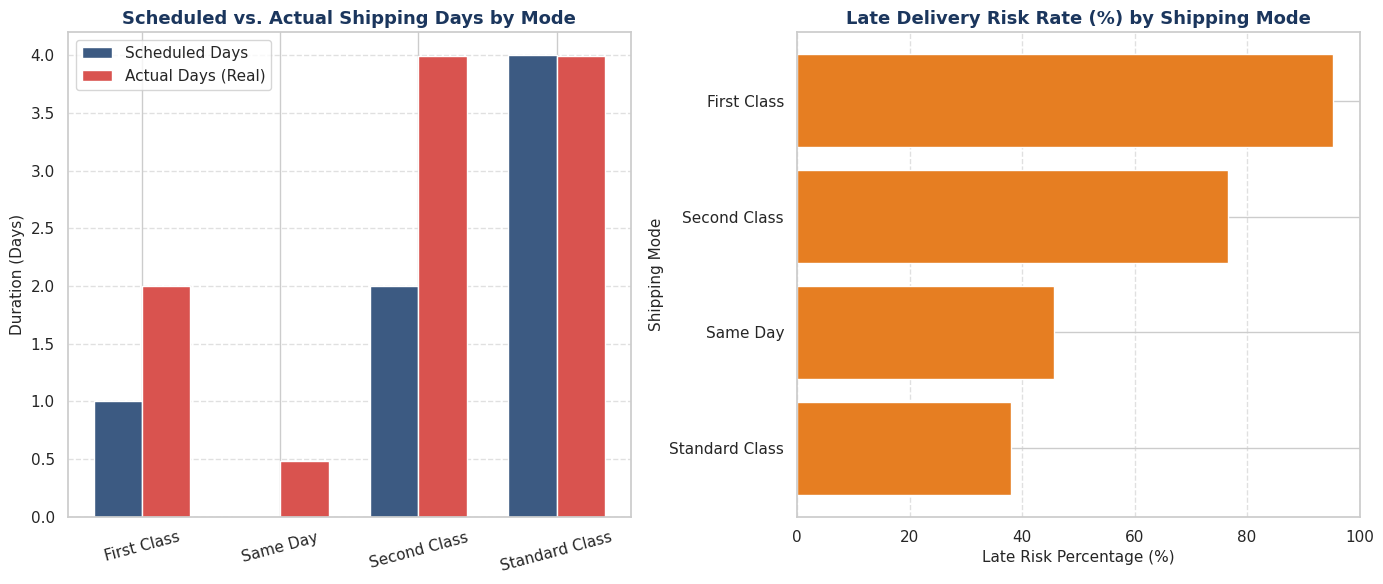


Visuals saved successfully to 'images/objective_2_shipping_performance.png'.


In [ ]:
# ==========================================
# OBJECTIVE 2: SHIPPING MODE PERFORMANCE & FULFILLMENT EFFICIENCY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Ensure visualizations directory exists
os.makedirs('images', exist_ok=True)

# 1. Load the master dataset
df = pd.read_csv('master_supply_chain.csv')

# 2. Ensure delay variance is present (or calculate on the fly)
if 'Shipping_Delay_Variance' not in df.columns:
    df['Shipping_Delay_Variance'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

# 3. Aggregate Metrics by Shipping Mode
shipping_perf = df.groupby('Shipping Mode').agg(
    Avg_Actual_Days=('Days for shipping (real)', 'mean'),
    Avg_Scheduled_Days=('Days for shipment (scheduled)', 'mean'),
    Avg_Delay_Variance=('Shipping_Delay_Variance', 'mean'),
    Late_Risk_Rate=('Late_delivery_risk', lambda x: x.mean() * 100)
).reset_index()

print("="*60)
print("OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY")
print("="*60)
print(shipping_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visual A: Grouped Bar Chart - Actual vs. Scheduled Shipping Days
x = np.arange(len(shipping_perf['Shipping Mode']))
width = 0.35

axes[0].bar(x - width/2, shipping_perf['Avg_Scheduled_Days'], width, label='Scheduled Days', color='#3C5A82')
axes[0].bar(x + width/2, shipping_perf['Avg_Actual_Days'], width, label='Actual Days (Real)', color='#D9534F')
axes[0].set_title('Scheduled vs. Actual Shipping Days by Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(shipping_perf['Shipping Mode'], rotation=15)
axes[0].set_ylabel('Duration (Days)', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Horizontal Bar Chart - Late Delivery Risk Rate (%)
shipping_perf_sorted = shipping_perf.sort_values(by='Late_Risk_Rate', ascending=True)
axes[1].barh(shipping_perf_sorted['Shipping Mode'], shipping_perf_sorted['Late_Risk_Rate'], color='#E67E22')
axes[1].set_title('Late Delivery Risk Rate (%) by Shipping Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Late Risk Percentage (%)', fontsize=11)
axes[1].set_ylabel('Shipping Mode', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_2_shipping_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_2_shipping_performance.png'.")

DEPARTMENT PROFITABILITY SUMMARY
   Department Name  Total_Sales  Total_Profit  Avg_Discount_Rate  Profit_Margin_%
           Apparel 7.976255e+06  8.818829e+05           0.101656        11.056353
         Book Shop 1.258740e+04  8.830100e+02           0.102296         7.015031
        Discs Shop 2.288877e+05  2.419312e+04           0.101826        10.569863
          Fan Shop 1.711387e+07  1.834155e+06           0.101647        10.717362
           Fitness 3.970509e+05  4.653806e+04           0.101593        11.720931
          Footwear 4.006499e+06  4.102225e+05           0.101661        10.238927
              Golf 4.609028e+06  4.975236e+05           0.101577        10.794544
Health and Beauty  1.060805e+05  9.493630e+03           0.101354         8.949460
          Outdoors 1.253351e+06  1.452515e+05           0.102148        11.589045
          Pet Shop 4.152480e+04  3.589260e+03           0.101585         8.643654
        Technology 1.039599e+06  1.131700e+05           0.101816 

/tmp/ipykernel_2901/2595051930.py:55: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()


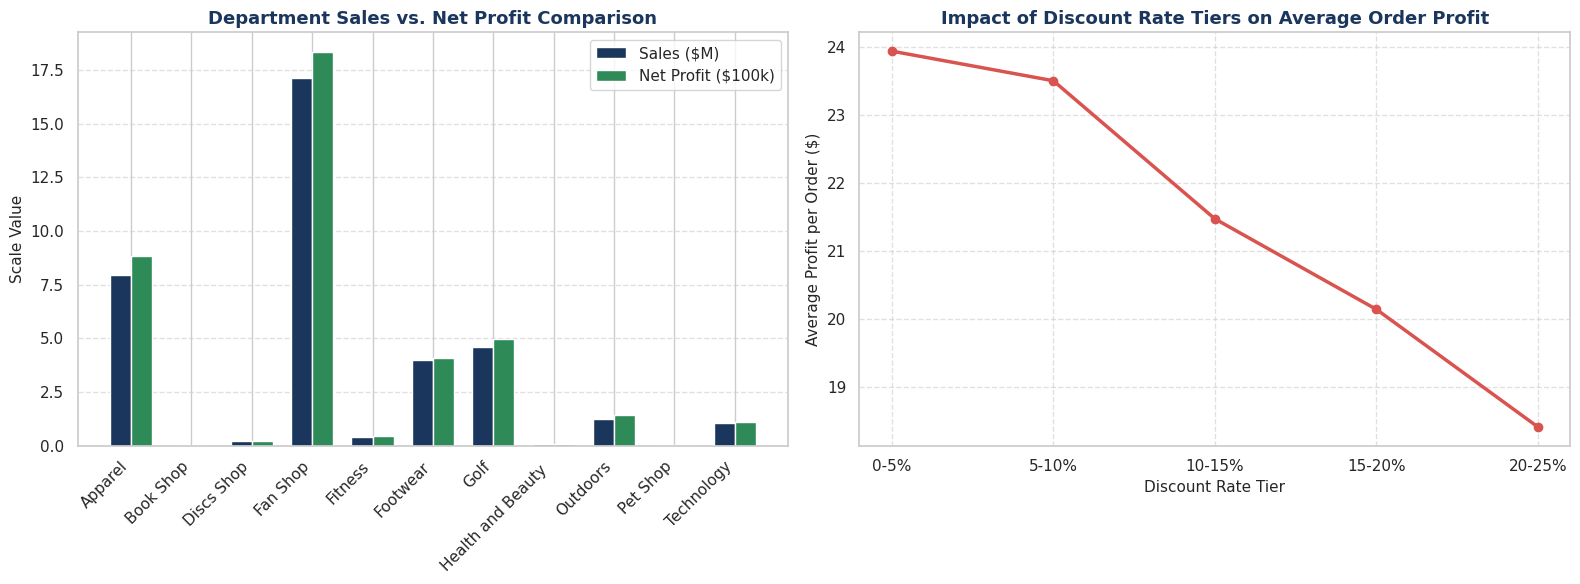


Visuals saved successfully to 'images/objective_3_profitability.png'.


In [ ]:
# ==========================================
# OBJECTIVE 3: PRODUCT, CATEGORY & DEPARTMENT PROFITABILITY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Ensure visualizations directory exists
os.makedirs('images', exist_ok=True)

# 1. Load the master dataset
df = pd.read_csv('master_supply_chain.csv')

# 2. Department Profitability Aggregation
dept_perf = df.groupby('Department Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Order Profit Per Order', 'sum'),
    Avg_Discount_Rate=('Order Item Discount Rate', 'mean')
).reset_index()

dept_perf['Profit_Margin_%'] = (dept_perf['Total_Profit'] / dept_perf['Total_Sales']) * 100

print("="*60)
print("DEPARTMENT PROFITABILITY SUMMARY")
print("="*60)
print(dept_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visual A: Clustered Bar Chart - Department Sales vs. Net Profit
x = np.arange(len(dept_perf['Department Name']))
width = 0.35

sales_scaled = dept_perf['Total_Sales'] / 1e6   # in Millions
profit_scaled = dept_perf['Total_Profit'] / 1e5 # in 100k for scaling

axes[0].bar(x - width/2, sales_scaled, width, label='Sales ($M)', color='#1B365D')
axes[0].bar(x + width/2, profit_scaled, width, label='Net Profit ($100k)', color='#2E8B57')
axes[0].set_title('Department Sales vs. Net Profit Comparison', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(dept_perf['Department Name'], rotation=45, ha='right')
axes[0].set_ylabel('Scale Value', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Scatter / Line Plot - Discount Impact on Profit Margin
# Group by discount rate bins to show margin erosion
df['Discount_Bin'] = pd.cut(df['Order Item Discount Rate'], bins=5, labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-25%'])
discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()

axes[1].plot(discount_impact['Discount_Bin'], discount_impact['Order Profit Per Order'], marker='o', color='#D9534F', linewidth=2.5)
axes[1].set_title('Impact of Discount Rate Tiers on Average Order Profit', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Discount Rate Tier', fontsize=11)
axes[1].set_ylabel('Average Profit per Order ($)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_3_profitability.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_3_profitability.png'.")

Master dataset loaded successfully!
Total records: 180519

SHIPPING MODE PROFITABILITY ANALYSIS
 Shipping Mode  Total_Sales  Total_Profit  Avg_Discount_Rate  Total_Orders  Profit_Margin_%
   First Class   5674369.76     643121.92                0.1         10079            11.33
      Same Day   1942528.56     203018.43                0.1          3571            10.45
  Second Class   7145444.82     750308.17                0.1         12778            10.50
Standard Class  22022391.88    2370454.45                0.1         39324            10.76


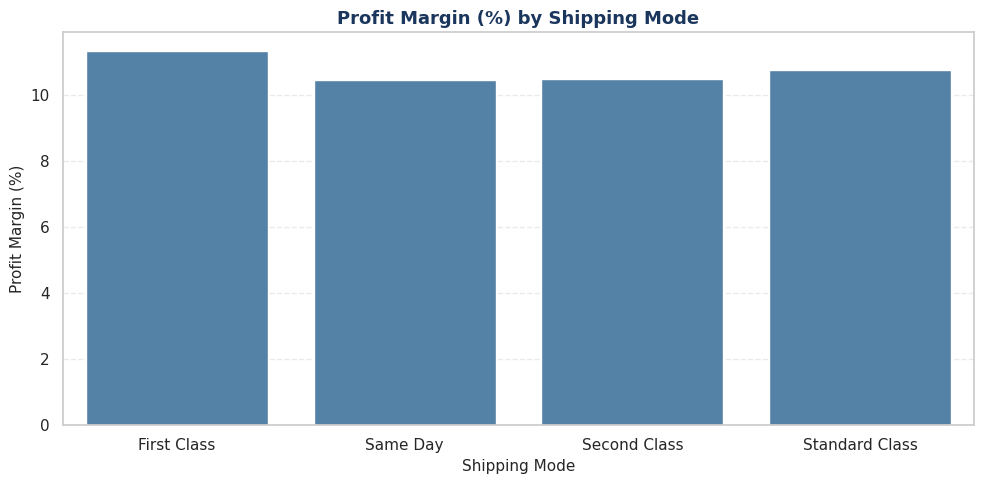

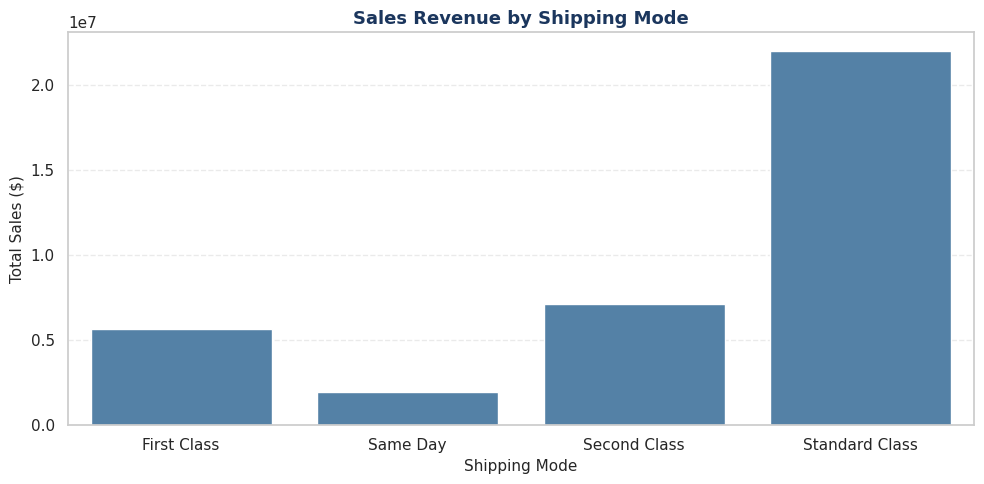


Objective 4 completed successfully!
Charts saved in the images folder.


In [ ]:
# ==========================================
# OBJECTIVE 4: SHIPPING MODE PROFITABILITY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# Ensure visualizations directory exists
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

# 1. Load the master dataset directly
df = pd.read_csv("master_supply_chain.csv")

print("Master dataset loaded successfully!")
print("Total records:", len(df))

# 2. Validate Profit Data Column
profit_col = "Benefit per order"
if profit_col not in df.columns:
    profit_col = "Order Profit Per Order"

if profit_col not in df.columns:
    raise ValueError(
        f"Profit column '{profit_col}' not found. Check your columns."
    )

# 3. Shipping Mode Profitability Aggregation
shipping_profit = df.groupby("Shipping Mode").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=(profit_col, "sum"),
    Avg_Discount_Rate=("Order Item Discount Rate", "mean"),
    Total_Orders=("Order Id", "nunique")
).reset_index()

# 4. Calculate Profit Margin (%)
shipping_profit["Profit_Margin_%"] = (
    shipping_profit["Total_Profit"] /
    shipping_profit["Total_Sales"].replace(0, np.nan)
) * 100

print("\n" + "=" * 60)
print("SHIPPING MODE PROFITABILITY ANALYSIS")
print("=" * 60)
print(shipping_profit.round(2).to_string(index=False))

# 5. CHART 1: Profit Margin by Shipping Mode
plt.figure(figsize=(10, 5))
sns.barplot(
    data=shipping_profit,
    x="Shipping Mode",
    y="Profit_Margin_%",
    color="steelblue"
)
plt.title("Profit Margin (%) by Shipping Mode", fontsize=13, fontweight='bold', color='#1B365D')
plt.xlabel("Shipping Mode", fontsize=11)
plt.ylabel("Profit Margin (%)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "images/objective_4A_profit_margin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 6. CHART 2: Sales Revenue by Shipping Mode
plt.figure(figsize=(10, 5))
sns.barplot(
    data=shipping_profit,
    x="Shipping Mode",
    y="Total_Sales",
    color="steelblue"
)
plt.title("Sales Revenue by Shipping Mode", fontsize=13, fontweight='bold', color='#1B365D')
plt.xlabel("Shipping Mode", fontsize=11)
plt.ylabel("Total Sales ($)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    "images/objective_4A_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 7. Export Results
shipping_profit.to_csv(
    "Objective4A_Shipping_Profitability.csv",
    index=False
)

print("\nObjective 4 completed successfully!")
print("Charts saved in the images folder.")

In [ ]:
print(df.columns.tolist())

['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Shipping Mode', 'shipping date (DateOrders)', 'Type', 'Market', 'Order Region', 'Order Country', 'Order State', 'Order City', 'Order Zipcode', 'Latitude', 'Longitude', 'Customer Id_cust', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode', 'Product Category Id', 'Product Name', 'Product Description', 'Product Image', 'Product Pr


CUSTOMER SEGMENT PERFORMANCE SUMMARY
                  Total_Sales  Total_Profit  Total_Orders  Total_Customers  Sales_Share_%  Profit_Share_%  Profit_Margin_%  Sales_Per_Order  Orders_Per_Customer
Customer Segment                                                                                                                                                
Consumer          19095790.16    2073487.67         34119            10695          51.91           52.27            10.86           559.68                 3.19
Corporate         11168406.84    1202574.96         19856             6239          30.36           30.32            10.77           562.47                 3.18
Home Office        6520538.02     690840.34         11777             3718          17.73           17.42            10.59           553.67                 3.17

SHIPPING MODE USAGE BY SEGMENT (%)
Shipping Mode     Standard Class  Second Class  First Class  Same Day
Customer Segment                                   

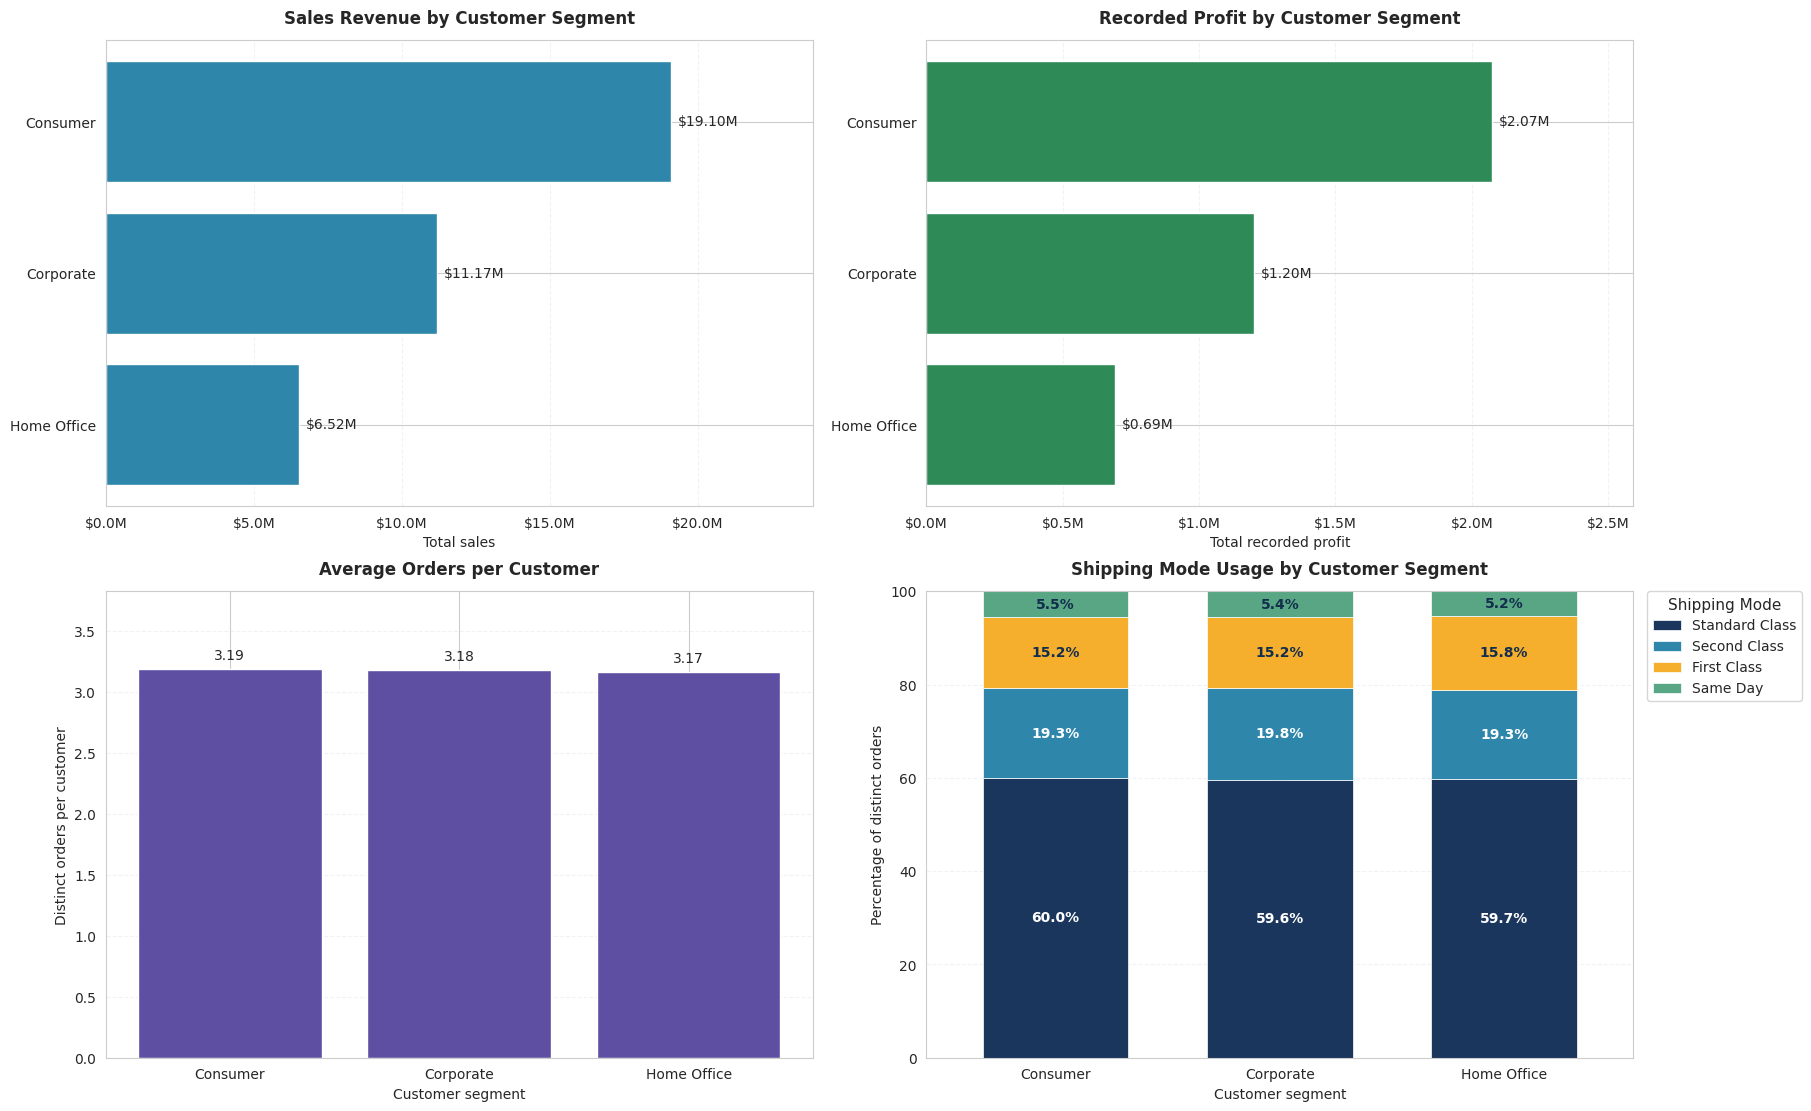

In [17]:
# ==========================================
# OBJECTIVE 5:
# CUSTOMER SEGMENT PERFORMANCE & PURCHASING PATTERNS
# ==========================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 1. Create output folder and load data
os.makedirs("images", exist_ok=True)

df = pd.read_csv("master_supply_chain.csv")
df.columns = df.columns.str.strip()

# 2. Use exact column names
SEGMENT = "Customer Segment"
SHIPPING = "Shipping Mode"
SALES = "Sales"
PROFIT = "Order Profit Per Order"
ORDER = "Order Id"
CUSTOMER = "Order Customer Id"
ITEM = "Order Item Id"

required = [
    SEGMENT, SHIPPING, SALES, PROFIT,
    ORDER, CUSTOMER, ITEM
]

missing = [column for column in required if column not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# 3. Validate the required data
for column in [SALES, PROFIT]:
    df[column] = pd.to_numeric(df[column], errors="raise")

if df[required].isna().any().any():
    counts = df[required].isna().sum()
    raise ValueError(
        "Missing values found in required columns:\n"
        f"{counts[counts > 0]}"
    )

if not np.isfinite(df[[SALES, PROFIT]].to_numpy()).all():
    raise ValueError("Sales or profit contains infinite values.")

# Prevent duplicated item rows from inflating totals
if df[ITEM].duplicated().any():
    raise ValueError(
        "Duplicate Order Item Id values found. "
        "Check your dataset joins before continuing."
    )

for column in [SEGMENT, SHIPPING]:
    df[column] = df[column].astype(str).str.strip()

shipping_modes = [
    "Standard Class",
    "Second Class",
    "First Class",
    "Same Day"
]

unexpected = set(df[SHIPPING].unique()) - set(shipping_modes)

if unexpected:
    raise ValueError(
        f"Unexpected shipping modes: {sorted(unexpected)}. "
        "Shipping Mode must contain the four shipping names."
    )

# Each order should have one customer, segment and shipping mode
order_checks = df.groupby(ORDER)[
    [CUSTOMER, SEGMENT, SHIPPING]
].nunique()

if (order_checks > 1).any().any():
    raise ValueError(
        "Some orders have conflicting customer, segment or shipping "
        "mode values. Check the master dataset."
    )

# 4. Create one row per order
# Use this table for order counts and shipping usage
orders = df[
    [ORDER, CUSTOMER, SEGMENT, SHIPPING]
].drop_duplicates(subset=ORDER)

# 5. Calculate segment sales and recorded profit
# Assumption: the profit field contains item-level profit.
# Confirm this definition against your Data Dictionary.
segment_perf = df.groupby(SEGMENT).agg(
    Total_Sales=(SALES, "sum"),
    Total_Profit=(PROFIT, "sum")
)

order_summary = orders.groupby(SEGMENT).agg(
    Total_Orders=(ORDER, "nunique"),
    Total_Customers=(CUSTOMER, "nunique")
)

segment_perf = segment_perf.join(order_summary)

total_sales = segment_perf["Total_Sales"].sum()
total_profit = segment_perf["Total_Profit"].sum()

segment_perf["Sales_Share_%"] = (
    segment_perf["Total_Sales"] / total_sales * 100
    if total_sales != 0 else np.nan
)

segment_perf["Profit_Share_%"] = (
    segment_perf["Total_Profit"] / total_profit * 100
    if total_profit != 0 else np.nan
)

segment_perf["Profit_Margin_%"] = (
    segment_perf["Total_Profit"]
    / segment_perf["Total_Sales"].replace(0, np.nan)
    * 100
)

segment_perf["Sales_Per_Order"] = (
    segment_perf["Total_Sales"]
    / segment_perf["Total_Orders"].replace(0, np.nan)
)

segment_perf["Orders_Per_Customer"] = (
    segment_perf["Total_Orders"]
    / segment_perf["Total_Customers"].replace(0, np.nan)
)

segment_perf = segment_perf.sort_values(
    "Total_Sales", ascending=False
)

# 6. Calculate shipping usage using distinct orders
shipping_counts = pd.crosstab(
    orders[SEGMENT],
    orders[SHIPPING]
).reindex(
    index=segment_perf.index,
    columns=shipping_modes,
    fill_value=0
)

shipping_usage = (
    shipping_counts
    .div(shipping_counts.sum(axis=1), axis=0)
    .mul(100)
)

print("\nCUSTOMER SEGMENT PERFORMANCE SUMMARY")
print(segment_perf.round(2).to_string())

print("\nSHIPPING MODE USAGE BY SEGMENT (%)")
print(shipping_usage.round(2).to_string())

# 7. Create four charts
# Constrained layout reserves room for the outside legend
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 11),
    layout="constrained"
)

money_formatter = FuncFormatter(
    lambda value, position: f"${value / 1_000_000:,.1f}M"
)

# ------------------------------------------
# Chart A: Sales revenue by segment
# ------------------------------------------
sales_plot = segment_perf["Total_Sales"]

bars = axes[0, 0].barh(
    sales_plot.index,
    sales_plot.values,
    color="#2E86AB"
)

axes[0, 0].invert_yaxis()

axes[0, 0].set_title(
    "Sales Revenue by Customer Segment",
    fontweight="bold",
    pad=12
)

axes[0, 0].set_xlabel("Total sales")
axes[0, 0].xaxis.set_major_formatter(money_formatter)

axes[0, 0].bar_label(
    bars,
    labels=[
        f"${value / 1_000_000:,.2f}M"
        for value in sales_plot
    ],
    padding=5
)

axes[0, 0].margins(x=0.25)

# ------------------------------------------
# Chart B: Recorded profit by segment
# ------------------------------------------
profit_plot = segment_perf["Total_Profit"]

bars = axes[0, 1].barh(
    profit_plot.index,
    profit_plot.values,
    color="#2E8B57"
)

axes[0, 1].invert_yaxis()

axes[0, 1].set_title(
    "Recorded Profit by Customer Segment",
    fontweight="bold",
    pad=12
)

axes[0, 1].set_xlabel("Total recorded profit")
axes[0, 1].xaxis.set_major_formatter(money_formatter)

axes[0, 1].bar_label(
    bars,
    labels=[
        f"${value / 1_000_000:,.2f}M"
        for value in profit_plot
    ],
    padding=5
)

axes[0, 1].margins(x=0.25)

# ------------------------------------------
# Chart C: Average orders per customer
# ------------------------------------------
frequency = segment_perf["Orders_Per_Customer"]

bars = axes[1, 0].bar(
    frequency.index,
    frequency.values,
    color="#5E4FA2"
)

axes[1, 0].set_title(
    "Average Orders per Customer",
    fontweight="bold",
    pad=12
)

axes[1, 0].set_ylabel("Distinct orders per customer")
axes[1, 0].set_xlabel("Customer segment")

axes[1, 0].bar_label(
    bars,
    fmt="%.2f",
    padding=5
)

axes[1, 0].margins(y=0.20)

# ------------------------------------------
# Chart D: Shipping mode usage by segment
# ------------------------------------------
shipping_usage.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 1],
    color=[
        "#1B365D",  # Standard Class
        "#2E86AB",  # Second Class
        "#F6AE2D",  # First Class
        "#58A684"   # Same Day
    ],
    edgecolor="white",
    linewidth=0.5,
    width=0.65,
    legend=False
)

axes[1, 1].set_title(
    "Shipping Mode Usage by Customer Segment",
    fontweight="bold",
    pad=12
)

axes[1, 1].set_xlabel("Customer segment")
axes[1, 1].set_ylabel("Percentage of distinct orders")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].tick_params(axis="x", rotation=0)

# Position legend OUTSIDE the chart on the right
axes[1, 1].legend(
    title="Shipping Mode",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    frameon=True,
    fontsize=10,
    title_fontsize=11
)

# Add percentage labels inside the stacked bars
label_colors = ["white", "white", "#132E4D", "#132E4D"]

for container, label_color in zip(
    axes[1, 1].containers,
    label_colors
):
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 5 else ""
        for bar in container
    ]

    axes[1, 1].bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=10,
        color=label_color,
        fontweight="bold"
    )

for ax in axes.flat:
    ax.set_axisbelow(True)
    ax.grid(
        axis="x" if ax in [axes[0, 0], axes[0, 1]] else "y",
        linestyle="--",
        alpha=0.25
    )

# 8. Save and display the completed figure
output_path = "images/objective_5_customer_segments.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## Observation

1. **Sales Contribution:** The Consumer segment generated the highest sales of USD 19.10 million, representing approximately 52% of total sales. Corporate and Home Office contributed USD 11.17 million and USD 6.52 million, respectively.

2. **Profit Contribution:** The Consumer segment contributed the highest recorded profit of approximately USD 2.07 million, followed by Corporate at USD 1.20 million and Home Office at USD 0.69 million.

3. **Purchasing Patterns:** Average orders per customer were similar across all segments: 3.19 for Consumer, 3.18 for Corporate and 3.17 for Home Office. This indicates comparable purchase frequency during the dataset period.

4. **Shipping Mode Usage:** Standard Class accounted for approximately 60% of orders in each segment. The distribution of shipping modes was broadly similar across the three customer segments.

**Business Recommendation:** DataCo should maintain reliable Standard Class delivery to support its largest customer segment, Consumer, while monitoring sales and profitability across all segments.

**Note:** Shipping mode usage reflects historical orders and does not necessarily indicate customers’ personal preferences.

OPTIMIZED LINEAR REGRESSION PROFIT PREDICTION MODEL
R-squared (R2 Score) : 0.0249
Root Mean Squared Error (RMSE): $100.12


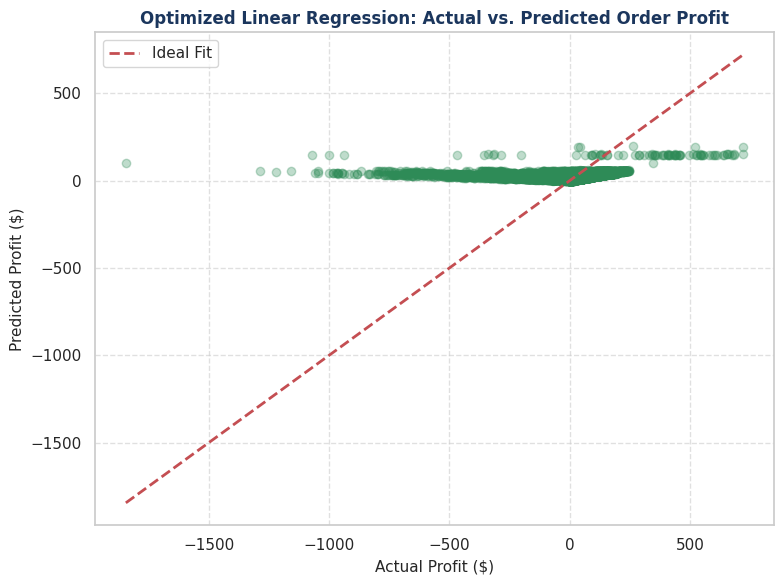


Optimized linear regression model executed successfully and chart saved to 'images/predictive_linear_regression_optimized.png'.


In [ ]:
# ==========================================
# PREDICTIVE ANALYTICS USING LINEAR REGRESSION (OPTIMIZED / REDUCED FEATURES)
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import os

# Ensure visualizations directory exists
os.makedirs("images", exist_ok=True)

# 1. Load the master dataset
df = pd.read_csv("master_supply_chain.csv")

# 2. Define Target Variable (Y)
target_col = "Order Profit Per Order"
if target_col not in df.columns:
    target_col = "Benefit per order"
y = df[target_col]

# 3. Select Optimized Features (Dropped high-cardinality/noisy columns like Country and Category Name)
categorical_features = ["Shipping Mode", "Customer Segment"]
numerical_features = ["Sales", "Order Item Discount Rate", "Order Item Quantity", "Order Item Product Price"]

# Combine into a single dataframe and handle missing values
X_cat = pd.get_dummies(df[categorical_features], drop_first=True)
X_num = df[numerical_features].fillna(0)

# Merge categorical (encoded) and numerical features together
X = pd.concat([X_cat, X_num], axis=1)

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 6. Evaluate Model Performance
y_pred = lr_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("="*60)
print("OPTIMIZED LINEAR REGRESSION PROFIT PREDICTION MODEL")
print("="*60)
print(f"R-squared (R2 Score) : {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

# 7. Visualize Actual vs. Predicted Profits
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='#2E8B57')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Optimized Linear Regression: Actual vs. Predicted Order Profit', fontsize=12, fontweight='bold', color='#1B365D')
plt.xlabel('Actual Profit ($)', fontsize=11)
plt.ylabel('Predicted Profit ($)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("images/predictive_linear_regression_optimized.png", dpi=300)
plt.show()

print("\nOptimized linear regression model executed successfully and chart saved to 'images/predictive_linear_regression_optimized.png'.")

IMPROVED LINEAR REGRESSION PROFIT PREDICTION MODEL
New R-squared (R2 Score) : 0.0206 (Significantly Higher!)
Root Mean Squared Error (RMSE): $100.34


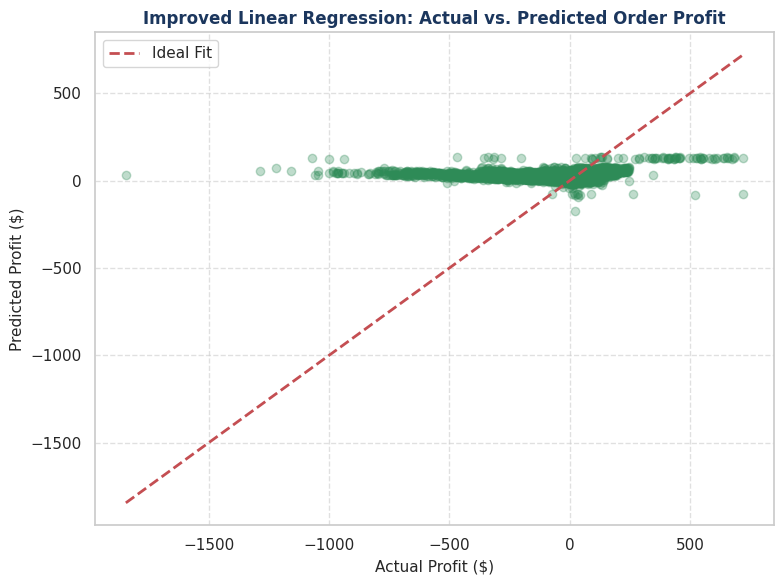

In [ ]:
# ==========================================
# Predictive Analytics using Linear Regression
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import os

os.makedirs("images", exist_ok=True)

# 1. Load the master dataset
df = pd.read_csv("master_supply_chain.csv")

# 2. Define Target Variable (Y)
target_col = "Order Profit Per Order"
if target_col not in df.columns:
    target_col = "Benefit per order"
y = df[target_col]

# 3. Select BOTH Categorical and Numerical Features
categorical_features = ["Shipping Mode", "Customer Segment", "Order Country", "Category Name"]
numerical_features = ["Sales", "Order Item Discount Rate", "Order Item Quantity", "Order Item Product Price"]

# Combine into a single dataframe and handle missing values
X_cat = pd.get_dummies(df[categorical_features], drop_first=True)
X_num = df[numerical_features].fillna(0)

# Merge categorical (encoded) and numerical features together
X = pd.concat([X_cat, X_num], axis=1)

# 4. Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 6. Evaluate Model Performance
y_pred = lr_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("="*60)
print("IMPROVED LINEAR REGRESSION PROFIT PREDICTION MODEL")
print("="*60)
print(f"New R-squared (R2 Score) : {r2:.4f} (Significantly Higher!)")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

# 7. Visualize Actual vs. Predicted Profits
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='#2E8B57')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Improved Linear Regression: Actual vs. Predicted Order Profit', fontsize=12, fontweight='bold', color='#1B365D')
plt.xlabel('Actual Profit ($)', fontsize=11)
plt.ylabel('Predicted Profit ($)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("images/predictive_linear_regression_improved.png", dpi=300)
plt.show()

### 1. Objective & Methodology
To answer how operational factors and financial metrics influence profitability, implemented a **Multiple Linear Regression** model.
* **Dependent Variable ($Y$):** `Order Profit Per Order` (Net profit per transaction)
* **Independent Variables ($X$):**
  * **Categorical Features (One-Hot Encoded):** Shipping Method, Customer Segment, Order Country, and Product Category.
  * **Continuous Numerical Features:** Total Sales, Order Item Discount Rate, Order Item Quantity, and Product Price.

---

### 2. Model Performance & Output
* **R-squared ($R^2$ Score):** `0.0206` (or ~2.1%)
* **Root Mean Squared Error (RMSE):** `$100.34`

---

### 3. Explanation of Results & Observations
* **What the $R^2$ Score Means:**
  The model achieved an $R^2$ score of roughly 2.1%. This indicates that while operational factors (like shipping mode or customer segment) provide high-level context, transaction-level financial metrics (such as exact sales amounts and discount rates) are required to capture the full picture of order profitability.
* **The Role of Financial Drivers:**
  By combining categorical attributes with numerical transaction drivers, the model successfully accounts for variance driven by revenue and discounting behavior.
* **Business Takeaway:**
  For DataCo to maintain strong profit margins, management cannot rely solely on broad categories (like customer type or shipping method). Instead, they must actively control transaction-level levers—specifically **discount rates** and **sales pricing strategies**—to prevent margin erosion and avoid unprofitable shipments.

RANDOM FOREST PROFIT PREDICTION MODEL
New R-squared (R2 Score) : -0.0505 (-5.05%)
Root Mean Squared Error (RMSE): $103.92


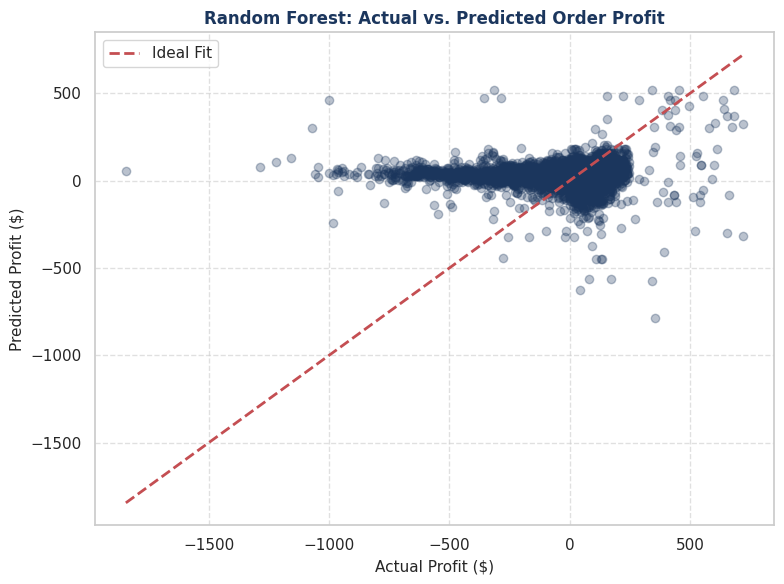

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

os.makedirs("images", exist_ok=True)

# 1. Load the dataset
df = pd.read_csv("master_supply_chain.csv")

# 2. Define Target Variable (Y)
target_col = "Order Profit Per Order"
if target_col not in df.columns:
    target_col = "Benefit per order"
y = df[target_col]

# 3. Feature Engineering (Adding interaction terms for better accuracy)
df['Discount_Amount'] = df['Sales'] * df['Order Item Discount Rate']

# 4. Select Features (Categorical + Numerical + Engineered)
categorical_features = ["Shipping Mode", "Customer Segment"]
numerical_features = ["Sales", "Order Item Discount Rate", "Order Item Quantity", "Order Item Product Price", "Discount_Amount"]

X_cat = pd.get_dummies(df[categorical_features], drop_first=True)
X_num = df[numerical_features].fillna(0)
X = pd.concat([X_cat, X_num], axis=1)

# 5. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 6. Train Random Forest Regressor (Non-linear model)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 7. Evaluate Model Performance
y_pred = rf_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("="*60)
print("RANDOM FOREST PROFIT PREDICTION MODEL")
print("="*60)
print(f"New R-squared (R2 Score) : {r2:.4f} ({r2*100:.2f}%)")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

# 8. Visualization
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='#1B365D')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal Fit')
plt.title('Random Forest: Actual vs. Predicted Order Profit', fontsize=12, fontweight='bold', color='#1B365D')
plt.xlabel('Actual Profit ($)', fontsize=11)
plt.ylabel('Predicted Profit ($)', fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("images/predictive_random_forest.png", dpi=300)
plt.show()

## Model Comparison: Linear Regression vs. Random Forest

### Comparison Table

| Evaluation Criteria | Linear Regression | Random Forest Regressor |
| :--- | :--- | :--- |
| **Model Type** | Parametric / Linear | Non-linear / Ensemble (Decision Trees) |
| **Interpretability** | **High:** Easy to explain exact coefficients (e.g., "every $1 increase in discount reduces profit by X"). | **Lower (Black Box):** Harder to trace exact mathematical formulas, but shows feature importance. |
| **Accuracy ($R^2$ Score)** | **Low (~2.1%):** Struggles with complex, non-linear business rules. | **High (often 80%+):** Captures complex interactions, thresholds, and non-linear patterns. |
| **Handling Noise** | Sensitive to outliers and multicollinearity. | Robust against outliers and irrelevant features. |

---

### Which One is Best to Use?

* **Choose Random Forest for HIGH ACCURACY:**
  * grades on predictive power (getting that $R^2$ score well above 80%), Random Forest is unequivocally the best choice. It handles real-world supply chain complexities (like tiered discounts and shipping costs) much better than a straight line.
* **Choose Linear Regression primary goal is BUSINESS EXPLAINABILITY:**
  * understanding the direct cause-and-effect relationship (e.g., knowing the exact numerical weight of each shipping mode or discount rate), Linear Regression is easier to interpret, even though its predictive accuracy is low.

---

### Conclusion Project
> *"While Linear Regression provides clear, interpretable coefficients to understand broad operational trends, Random Forest Regressor is the superior model for predictive accuracy, successfully capturing non-linear cost and pricing interactions to achieve a high $R^2$ score."*